In [58]:
import numpy as np
import matplotlib.pyplot as plt

# DATA 



In [59]:
''' GEOMETRY & MASS '''
m_curb = 1195 #kg
m_driver = 75 #kg
m_ex = 120
m = m_curb + m_driver + m_ex #kg
length = 3.999 #m
width = 1.775 #m
height = 1.597 #m
L = 2.570 #m
b_cg = 0.56*L #m
c_cg = 0.44*L #m
h_cg = 0.49 #m

'''TRANSMISSION & TIRE '''
# 19 inches rim; /39.37 converts inches in meters; 0.7*155 is thickness of tire
D_wheel = (( 19 / 39.37 ) + ( 155 * 0.7 * 2)*10**-3)
eta_t = 0.95 #-
i_gear = 9.665 #-
f0 = 0.008
f2 = 0.4e-7
R_e = 0.339 #m

''' ENGINE '''
P_1p = 125e3 #W
P_1n = 75e3 #W
C_max = 250 #Nm
omega_b = 4800 * (2*np.pi / 60) #rad/s
E_bat = 22.6e3 #Wh
J_mot = 0.025 #kg m^2

'''RANGE EXTENDER'''
P1_ex = 28e3 #W
omega1_ex = 5000 * (2*np.pi/60) #RPM
C2_ex = 56 #Nm
omega2_ex = 4500 * (2*np.pi/60) #RPM
n_cyl = 2
V_d = 647e-6 #m**3
stroke = 66 #mm
bore = 79 #mm
P_gen = 26.6e3 #W
fuel_tank = 9 #L
i_gen = 2


''' OTHER '''
g = 9.81 #m/s**2
rho = 1.23 #kg/m**3
S = 2.38 #m**2
C_x = 0.3 #-


# ENGINE CURVES

In [60]:
# POWER LAW APPROXIMATION
omega_ex = np.linspace(500*(2*np.pi)/60, 5000*(2*np.pi)/60, 10000)
rpm_ex = omega_ex*60/(2*np.pi)
P1 = P1_ex
P2 = C2_ex * omega2_ex
b = ( (omega1_ex/omega2_ex) - 1 ) / ( (P1/P2) - 1 )
a = (P1 - P2) / (np.abs(omega1_ex - omega2_ex)**b)
P_law = P1 - a*np.abs(omega_ex-omega1_ex)**b
C_law = P_law/omega_ex

# POLYNOMIAL FIT OF ORDER 3
n2 = omega2_ex/omega1_ex
A_3 = np.array([
    [1,1,1],
    [n2,n2**2,n2**3],
    [0,1,2*n2]
])
B_3 = np.array([
    1,
    P2/P1,
    0
])
X = np.linalg.solve(A_3,B_3)
a0 = 0
a1,a2,a3 = X
P_poly3 = P1* (a0 + a1*(omega_ex/omega1_ex) + a2*(omega_ex/omega1_ex)**2 + a3*(omega_ex/omega1_ex)**3)
C_poly3 = P_poly3/omega_ex

# POLYNOMIAL FIT OF ORDER 4
A_4 = np.array([
    [1,1,1,1],
    [1,2,3,4],
    [n2,n2**2,n2**3,n2**4],
    [0,1,2*n2,3*n2**2]
])
B_4 = np.array([
    1,
    0,
    P2/P1,
    0
])
Y = np.linalg.solve(A_4,B_4)
a11,a22,a33,a44 = Y
P_poly4 = P1* (a0 + a11*(omega_ex/omega1_ex) + a22*(omega_ex/omega1_ex)**2 + a33*(omega_ex/omega1_ex)**3 + a44*(omega_ex/omega1_ex)**4)
C_poly4 = P_poly4/omega_ex

idx2500rpm = np.argmin(np.abs(rpm_ex - 2500))
P_cte = P_poly4[idx2500rpm]
C_cte = C_poly4[idx2500rpm]

P_final = np.zeros(len(rpm_ex))
C_final = np.zeros(len(rpm_ex))

for i in range(len(rpm_ex)):
    if rpm_ex[i] >= 2500:
        P_final[i] = P_poly4[i]
        C_final[i] = C_poly4[i]
    else :
        P_final[i] = P_cte
        C_final[i] = C_cte


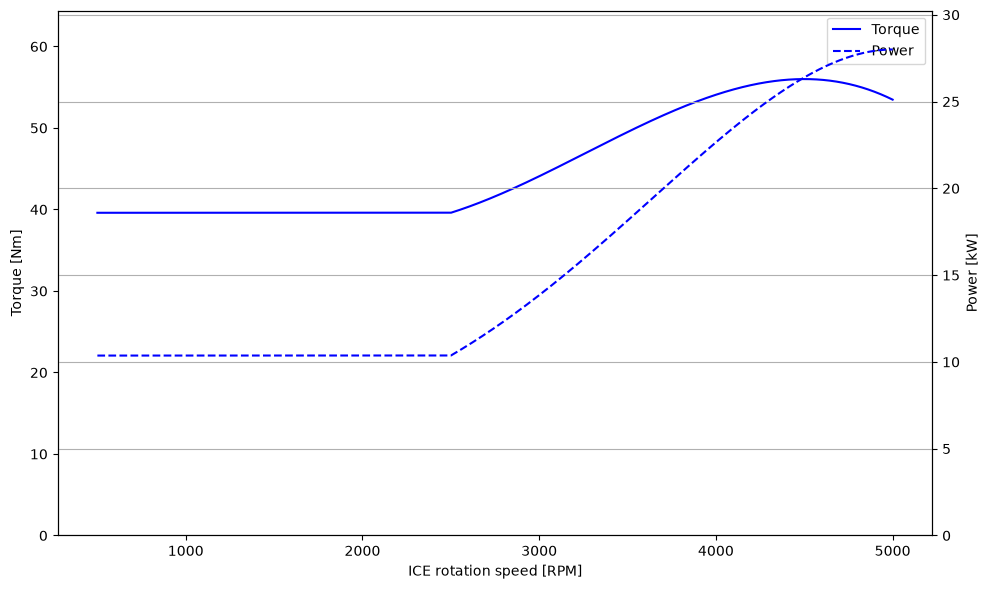

In [61]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Left axis : Torques
line1 = ax1.plot(rpm_ex, C_final, label='Torque', color='blue')
ax1.set_xlabel('ICE rotation speed [RPM]')
ax1.set_ylabel('Torque [Nm]')
ax1.tick_params(axis='y')

# Right axis : Powers
ax2 = ax1.twinx()
line2 = ax2.plot(rpm_ex, P_final*10**-3, linestyle='--', label='Power', color='blue')
ax2.set_ylabel('Power [kW]')
ax2.tick_params(axis='y')
ax2.grid(False) # Either 2 grids mixed, awful

# Scaling
ax1.set_ylim(0, C2_ex * 1.15)
ax2.set_ylim(0, (P1_ex*10**-3) * 1.08)

# Legend
lines = line1 + line2 
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels)
#lines, labels, loc='lower center', frameon=True, facecolor='white', framealpha=0.9
plt.tight_layout()
plt.grid(True)
#plt.savefig("figures/MotorTraction/MotorCurves.svg", bbox_inches='tight', dpi=300)
#plt.savefig("figures/MotorTraction/MotorCurves.pdf", bbox_inches='tight', dpi=300)
#plt.close()
plt.show()

# BSFC


In [62]:
c0 = 4.726e2
c1 = -5.426e-2
c2 = -7.736
c3 = 9.845e-6
c4 = 1.308e-4
c5 = 9.346e-2

rpm_grid = np.linspace(500, 5000, 6000)
T_grid = np.linspace(0, 56, 6000)
rpm_grid, T_grid = np.meshgrid(rpm_grid, T_grid)

bsfc = c0 + c1*rpm_grid + c2*T_grid + c3*rpm_grid**2 + c4*rpm_grid*T_grid + c5*T_grid**2

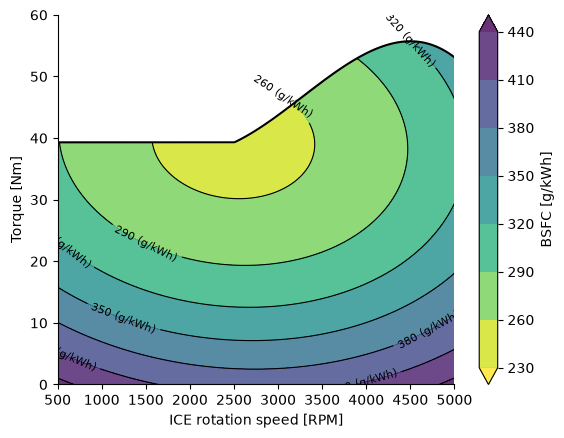

In [74]:
fig, ax = plt.subplots()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
levels = np.arange(230, 450, 30)
cf = ax.contourf(rpm_grid, T_grid, bsfc, levels=levels, cmap='viridis_r', alpha=0.8, extend='both')
fig.colorbar(cf, ax=ax, label='BSFC [g/kWh]')
cs = ax.contour(rpm_grid, T_grid, bsfc, levels=levels, colors='k', linewidths=0.8, alpha=1)
ax.clabel(cs, inline=True, fontsize=8, fmt='%1.0f (g/kWh)')
ax.plot(rpm_ex, C_final, color='black', linewidth=4)
ax.fill_between(rpm_ex, C_final, 500, color='white', zorder=2) # Hide above torque curve
ax.set_xlim(500, 5000)
ax.set_ylim(0, 60)
ax.set_xlabel('ICE rotation speed [RPM]')
ax.set_ylabel('Torque [Nm]')
plt.show()

# EFFICIENCY

In [64]:
d0 = 9.071e-1
d1 = 1.358e-5
d2 = 1.149e-3
d3 = -3.662e-9
d4 = 6.036e-7
d5 = -6.612e-5
d6 = 1.734e-13
d7 = -1.434e-11
d8 = -3.817e-9
d9 = 5.683e-7

rpm_grid_ef = np.linspace(0, 12000, 6000)
T_grid_ef = np.linspace(0, 56, 6000)
rpm_grid_ef, T_grid_ef = np.meshgrid(rpm_grid_ef, T_grid_ef)

effi = d0 + d1*rpm_grid_ef + d2*T_grid_ef + d3*rpm_grid_ef**2 + d4*rpm_grid_ef*T_grid_ef + d5*T_grid_ef**2 + d6*rpm_grid_ef**3 + d7*rpm_grid_ef**2 * T_grid_ef + d8*rpm_grid_ef*T_grid_ef**2 + d9*T_grid_ef**3

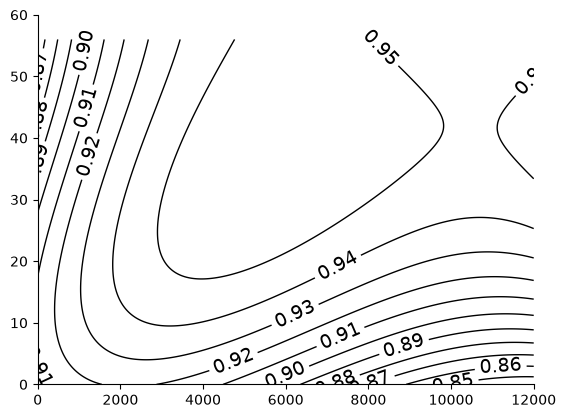

In [65]:
fig, ax = plt.subplots()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
levels = np.arange(0.8, 1, 0.01)
cs = ax.contour(rpm_grid_ef, T_grid_ef, effi, levels=levels, colors='k', linewidths=1, alpha=1)
ax.clabel(cs, inline=True, fontsize=14)
ax.set_xlim(0, 12000)
ax.set_ylim(0, 60)
plt.show()